# Evolução das dicas geradas

Cada **rodada** é uma amostra de dicas geradas pelo caminho real da API (`uv run adia amostra-de-dicas`)
marcada à mão como serve/não serve. Treinar aqui é ajustar os papéis (`backend/adia/ia/subagentes/papeis.py`)
e o filtro de qualidade (`backend/adia/guarda/qualidade.py`) entre uma rodada e outra; o peso do modelo não muda.

Fluxo de uma rodada nova:

1. ajustar papel ou filtro e commitar;
2. `uv run adia amostra-de-dicas` grava `docs/relatorios/revisao-dicas-<data>.csv`;
3. preencher `serve (s/n)` e `comentario` na planilha;
4. reexecutar este caderno (`uv run --with ipykernel --with matplotlib --with nbconvert jupyter nbconvert --to notebook --execute --inplace ml/cadernos/evolucao-dicas.ipynb`; sem rede, com `--offline` depois de `uv run`).

Só entram as planilhas com todas as linhas marcadas.

O Jupyter roda num ambiente avulso (`--with`), fora do `uv.lock`: assim a pilha dele não entra no fecho de dependências que a triagem de rede (DO-17) exige ler pacote a pacote.

In [1]:
import csv
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

from adia.caminhos import encontrar_raiz
from adia.guarda.qualidade import motivo_de_pobreza
from adia.nucleo.itens.carregador import arquivos_de_itens, carregar
from adia.tipos import Nivel

RAIZ = encontrar_raiz()
PREFIXO = "dica gerada fora do padrão do nível: "
itens = {i.id: i for i in carregar(arquivos_de_itens(RAIZ / "data" / "itens")).itens}

rodadas = {}
for arquivo in sorted((RAIZ / "docs" / "relatorios").glob("revisao-dicas-*.csv")):
    with arquivo.open(encoding="utf-8-sig", newline="") as f:
        linhas = list(csv.DictReader(f, delimiter=";"))
    if linhas and all(l["serve (s/n)"].strip() in ("s", "n") for l in linhas):
        rodadas[arquivo.stem.removeprefix("revisao-dicas-")] = linhas
print(len(rodadas), "rodada(s) marcada(s):", ", ".join(rodadas))

10 rodada(s) marcada(s): 2026-11-03, 2026-11-04, 2026-11-04b, 2026-11-04c, 2026-11-04d-3b, 2026-11-04e-3b, 2026-11-04f-3b, 2026-11-04g-3b, 2026-11-04h-3b, 2026-11-04i-3b


## Placar por rodada

- **aproveitamento**: dicas que passam no filtro *e* servem, sobre o total gerado. É o que mais importa: dica gerada boa chegando ao estudante.
- **precisão**: das que passam, quantas servem. Dica ruim que passa chega ao estudante.
- **descarte indevido**: dicas boas barradas, que viram a pré-escrita (perde-se a adaptação, não a segurança).
- **latência**: mediana do tempo de geração; **sem resp.**: gerações que falharam ou estouraram os 20 s (viram a pré-escrita).

In [2]:
from statistics import median

def placar(linhas):
    passou = [l for l in linhas if l["filtro"] == "passou"]
    barrou = [l for l in linhas if l["filtro"] != "passou"]
    boas_que_passam = sum(l["serve (s/n)"] == "s" for l in passou)
    # As planilhas anteriores à coluna `modelo` são todas do modelo de D14.
    ms = [int(l["ms"]) for l in linhas if l.get("ms")]
    return {
        "modelo": linhas[0].get("modelo") or "qwen2.5:1.5b",
        "geradas": len(linhas),
        "passaram": len(passou),
        "aproveitamento": boas_que_passam / len(linhas),
        "precisao": boas_que_passam / len(passou) if passou else 0.0,
        "ruins_que_passam": len(passou) - boas_que_passam,
        "descarte_indevido": sum(l["serve (s/n)"] == "s" for l in barrou),
        "ms_mediana": f"{median(ms) / 1000:.1f} s" if ms else "-",
        "sem_resposta": sum(not l["gerada_pelo_modelo"] for l in linhas),
    }

tabela = {nome: placar(linhas) for nome, linhas in rodadas.items()}
print(f"{'rodada':<16}{'modelo':<14}{'geradas':>8}{'passaram':>9}{'aprov.':>8}{'precisão':>9}"
      f"{'ruins ok':>9}{'desc. ind.':>11}{'latência':>10}{'sem resp.':>10}")
for nome, p in tabela.items():
    print(f"{nome:<16}{p['modelo']:<14}{p['geradas']:>8}{p['passaram']:>9}{p['aproveitamento']:>8.0%}"
          f"{p['precisao']:>9.0%}{p['ruins_que_passam']:>9}{p['descarte_indevido']:>11}{p['ms_mediana']:>10}"
          f"{p['sem_resposta']:>10}")

rodada          modelo         geradas passaram  aprov. precisão ruins ok desc. ind.  latência sem resp.
2026-11-03      qwen2.5:1.5b        58       44     53%      70%       13          3         -         0
2026-11-04      qwen2.5:1.5b        61       43     49%      70%       13          5         -         0
2026-11-04b     qwen2.5:1.5b        61       46     46%      61%       18          0         -         0
2026-11-04c     qwen2.5:1.5b        61       43     48%      67%       14          0         -         0
2026-11-04d-3b  qwen2.5:3b          62       54     74%      85%        8          1     7.6 s         4
2026-11-04e-3b  qwen2.5:3b          65       54     62%      74%       14          2     8.1 s         0
2026-11-04f-3b  qwen2.5:3b          61       55     70%      78%       12          3     7.7 s         0
2026-11-04g-3b  qwen2.5:3b          59       44     47%      64%       16          3     7.5 s         0
2026-11-04h-3b  qwen2.5:3b         113       97     63%

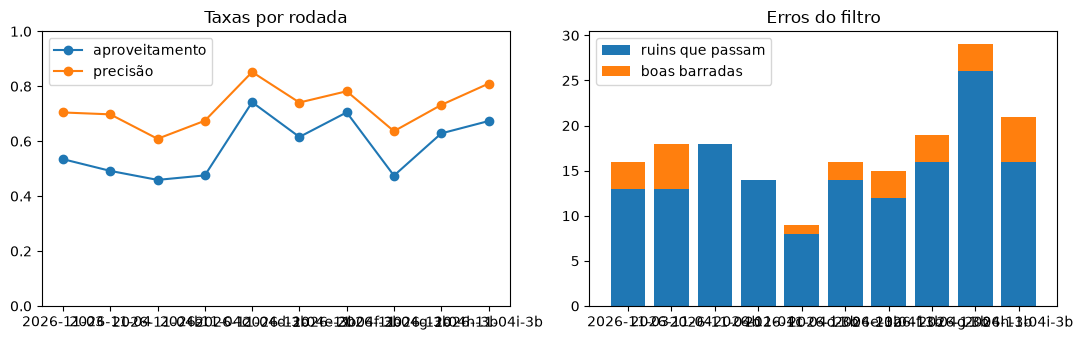

In [3]:
nomes = list(tabela)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
a.plot(nomes, [tabela[n]["aproveitamento"] for n in nomes], marker="o", label="aproveitamento")
a.plot(nomes, [tabela[n]["precisao"] for n in nomes], marker="o", label="precisão")
a.set_ylim(0, 1); a.set_title("Taxas por rodada"); a.legend()
b.bar(nomes, [tabela[n]["ruins_que_passam"] for n in nomes], label="ruins que passam")
b.bar(nomes, [tabela[n]["descarte_indevido"] for n in nomes],
      bottom=[tabela[n]["ruins_que_passam"] for n in nomes], label="boas barradas")
b.set_title("Erros do filtro"); b.legend()
fig.tight_layout()

## O filtro de hoje sobre todas as rodadas

Todas as linhas já marcadas formam um conjunto de regressão: o filtro atual é reaplicado a elas. Uma mudança no filtro
que piora alguma rodada antiga aparece aqui. Linhas barradas pela guarda de vazamento ficam de fora, porque o filtro de
qualidade não as vê.

In [4]:
def filtro_atual(l):
    return motivo_de_pobreza(l["gerada_pelo_modelo"], itens[l["item"]], Nivel[l["nivel"]])

for nome, linhas in rodadas.items():
    vistas = [l for l in linhas if not l["filtro"].startswith("guarda")]
    m = Counter((l["serve (s/n)"], filtro_atual(l) is None) for l in vistas)
    print(f"{nome}: boas que passam {m['s', True]}, ruins barradas {m['n', False]}, "
          f"ruins que passam {m['n', True]}, boas barradas {m['s', False]}")

2026-11-03: boas que passam 33, ruins barradas 12, ruins que passam 10, boas barradas 1
2026-11-04: boas que passam 35, ruins barradas 13, ruins que passam 10, boas barradas 0
2026-11-04b: boas que passam 28, ruins barradas 24, ruins que passam 7, boas barradas 0
2026-11-04c: boas que passam 29, ruins barradas 17, ruins que passam 12, boas barradas 0
2026-11-04d-3b: boas que passam 45, ruins barradas 6, ruins que passam 8, boas barradas 2
2026-11-04e-3b: boas que passam 40, ruins barradas 8, ruins que passam 14, boas barradas 2
2026-11-04f-3b: boas que passam 43, ruins barradas 3, ruins que passam 12, boas barradas 2
2026-11-04g-3b: boas que passam 28, ruins barradas 9, ruins que passam 15, boas barradas 3
2026-11-04h-3b: boas que passam 71, ruins barradas 9, ruins que passam 26, boas barradas 3
2026-11-04i-3b: boas que passam 68, ruins barradas 13, ruins que passam 14, boas barradas 5


## Motivos de descarte por rodada

In [5]:
for nome, linhas in rodadas.items():
    motivos = Counter(l["filtro"].removeprefix(PREFIXO) for l in linhas if l["filtro"] != "passou")
    print(nome, dict(motivos.most_common()))

2026-11-03 {'repete_o_enunciado': 5, 'sem_pergunta': 5, 'guarda descartou a dica gerada': 2, 'operacao_no_conceito': 1, 'curta': 1}
2026-11-04 {'repete_o_enunciado': 7, 'sem_pergunta': 4, 'guarda descartou a dica gerada': 3, 'inverte_a_operacao': 2, 'pergunta_fechada': 1, 'operacao_no_conceito': 1}
2026-11-04b {'sem_pergunta': 5, 'inverte_a_operacao': 3, 'repete_o_enunciado': 2, 'guarda descartou a dica gerada': 2, 'pergunta_fechada': 1, 'escreve_conta': 1, 'operacao_no_conceito': 1}
2026-11-04c {'sem_pergunta': 6, 'guarda descartou a dica gerada': 3, 'inverte_a_operacao': 3, 'pergunta_fechada': 2, 'operacao_no_conceito': 1, 'escreve_conta': 1, 'repete_o_enunciado': 1, 'numero_fora_do_enunciado': 1}
2026-11-04d-3b {'IA indisponível': 4, 'repete_o_enunciado': 2, 'inverte_a_operacao': 1, 'guarda descartou a dica gerada': 1}
2026-11-04e-3b {'repete_o_enunciado': 5, 'inverte_a_operacao': 2, 'numero_fora_do_enunciado': 2, 'sem_pergunta': 1, 'guarda descartou a dica gerada': 1}
2026-11-04f-3

## O que ainda passa e não serve, na última rodada

É a lista de onde vem o próximo ajuste.

In [6]:
ultima = list(rodadas)[-1]
for l in rodadas[ultima]:
    if l["filtro"] == "passou" and l["serve (s/n)"] == "n":
        print(f"{l['n']:>3} {l['nivel']} {l['item']}: {l['comentario']}")

  2 L1 alg-eq-101: rótulo 'Dica:' no início
  4 L1 alg-eq-101: rótulo 'Dica:' no início
 33 L2 alg-eq-104: longo, indica o passo
 36 L1 alg-eq-105: confusa
 38 L1 alg-eq-105: confusa: os termos já estão nos dois lados
 39 L1 alg-eq-105: confusa
 46 L2 alg-eq-106: português quebrado: 'mantém sua verdadeira'
 68 L2 alg-eq-109: confuso: distributiva não desfaz a multiplicação
 70 L2 alg-eq-109: a multiplicação está fora dos parênteses
 72 L1 alg-eq-110: português quebrado
 77 L2 alg-eq-110: 'encontrá-la' sem sentido
 81 L2 alg-eq-110: idem
 85 L1 alg-eq-111: 'incógnita em ambos os termos' errado
 89 L3 alg-eq-111: dois passos no L3
 91 L3 alg-eq-111: três passos no L3
101 L3 alg-eq-112: dividir por 2 não é passo de 5(t - 3) = 2t + 9
